# Q2C | Analyze Relationships Between Attributes

> Analyze the relationships between the data attributes, and between the data attributes and label. This involves computing the Pearson Correlation Coefficient (PCC) and generating scatter plots.

**IMPORTANT**

This dataset has no train / test split of its own, so the same chronological split as Q2B is made at the top of this notebook: the earliest 584 days are train and the latest 147 days are test. Every statistic and every score below is computed on the training rows only, so no analysis or treatment decision is influenced by the test data (data snooping).

# Answer Summary

TODO: _after full update_

---

# Imports

In [1]:
import pandas as pd
from IPython.display import display

import Q2.consts as Q2_CONSTS
from consts import TEST_SIZE

from utils import (
	read_csv_to_df,
	SPLIT,
	STATISTICS,
	PLOTTING,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)

# Fetch Data

In [2]:
df = read_csv_to_df(path=Q2_CONSTS.DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=Q2_CONSTS.SHORT_NAMES)

# Train / Test Split

In [3]:
train_df, test_df = SPLIT.chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

pd.DataFrame({
	"rows": [len(train_df), len(test_df)],
	"% of rows": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
	"first date": [f"{train_df['Date'].min():%Y-%m-%d}", f"{test_df['Date'].min():%Y-%m-%d}"],
	"last date": [f"{train_df['Date'].max():%Y-%m-%d}", f"{test_df['Date'].max():%Y-%m-%d}"],
}, index=["train", "test"])

,rows,% of rows,first date,last date
train,584,79.89,2011-01-01,2012-08-06
test,147,20.11,2012-08-07,2012-12-31


# Attribute Groups

In [4]:
CONTINUOUS = ["Temp", "FeelsLike", "Humidity", "Wind"]
BINARY = ["Year", "IsHoliday", "IsWorkday"]
MULTI_LEVEL = ["Season", "Month", "Weekday", "Weather"]

ATTRIBUTES = CONTINUOUS + BINARY + MULTI_LEVEL

print(f"{len(ATTRIBUTES)} attributes: {', '.join(ATTRIBUTES)}")
print(f"left out: {', '.join(col for col in train_df.columns if col not in ATTRIBUTES + [Q2_CONSTS.TARGET])}")

11 attributes: Temp, FeelsLike, Humidity, Wind, Year, IsHoliday, IsWorkday, Season, Month, Weekday, Weather
left out: ID, Date, Casual, Registered


# Attribute vs Attribute and Label

## Scatter Matrix

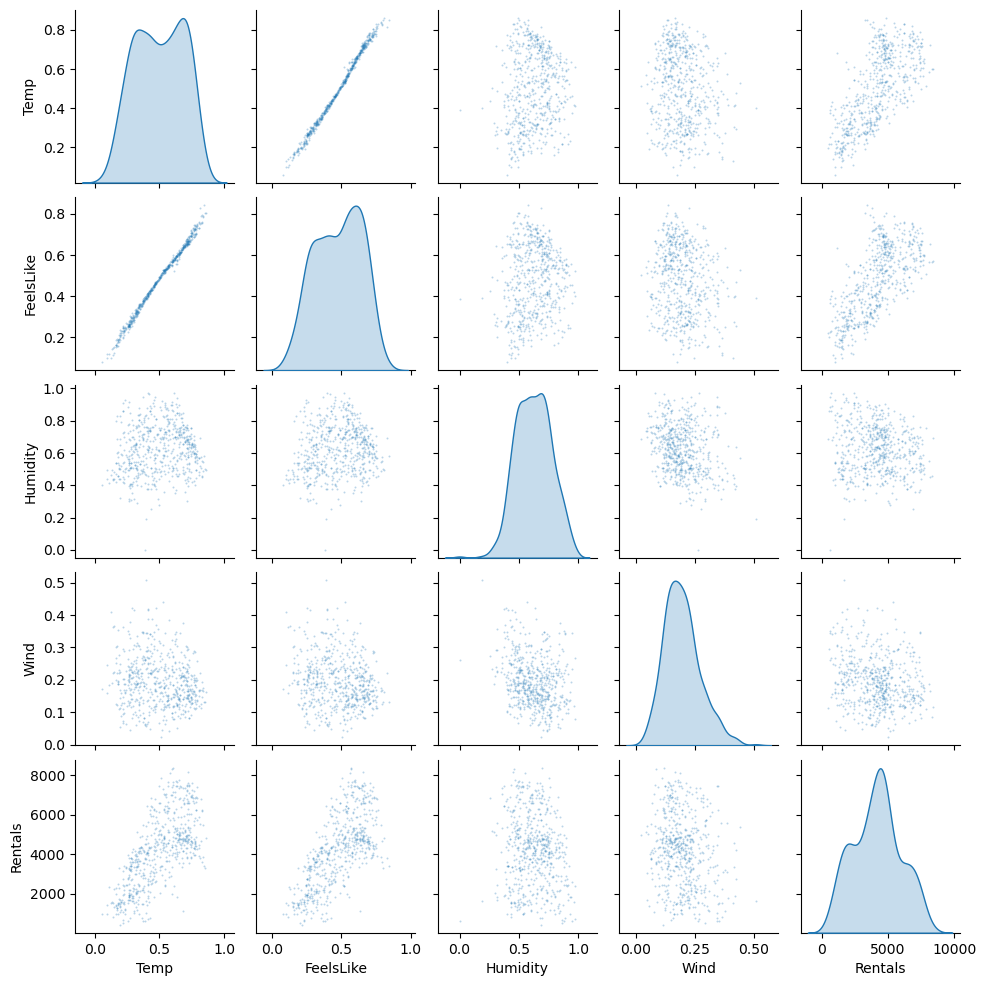

In [5]:
PLOTTING.scatter_matrix(df=train_df[CONTINUOUS + [Q2_CONSTS.TARGET]]);

### Notes / Observations

TODO: _after full update_

## Correlation

<Axes: title={'center': 'Pearson (lower) vs Spearman (upper) Correlation Matrix (train)'}>

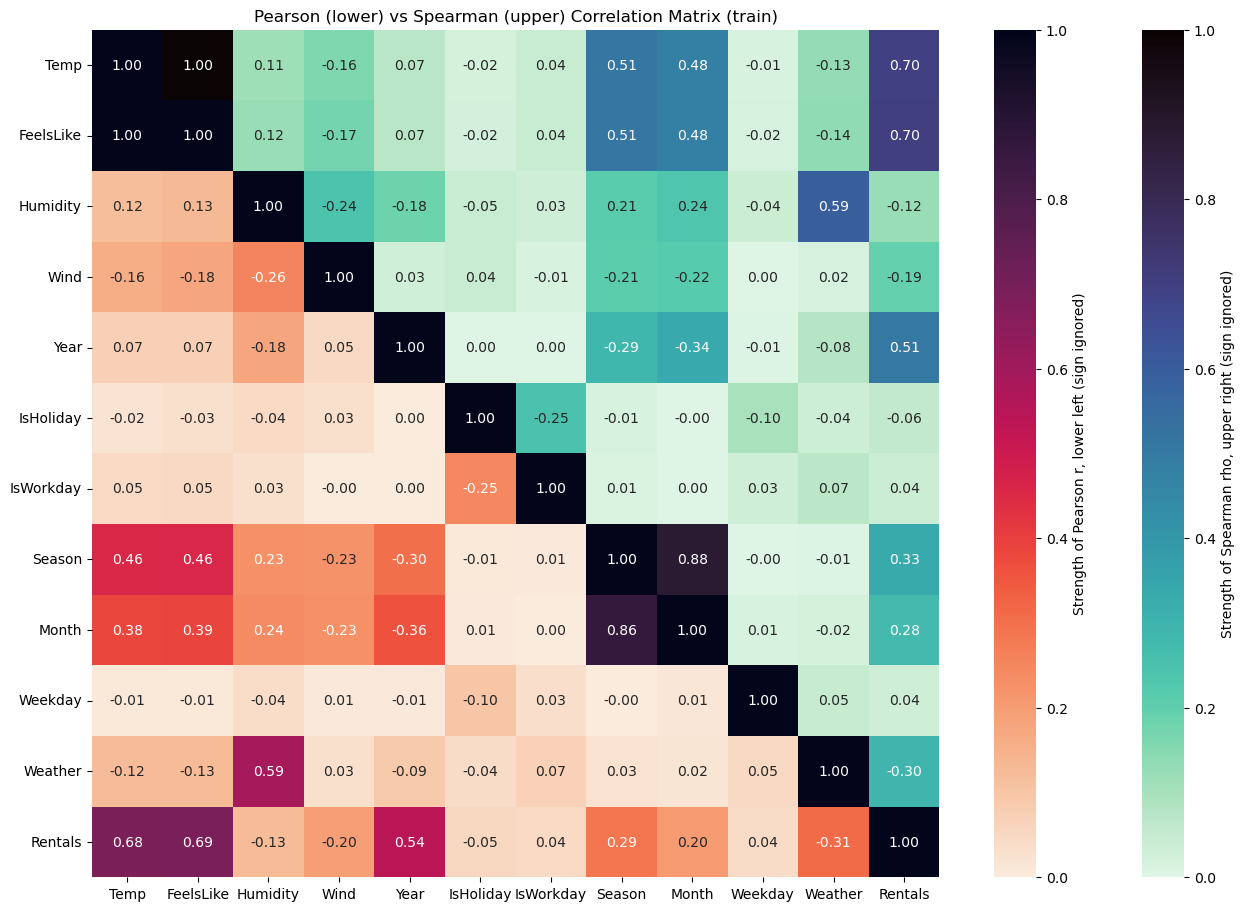

In [6]:
PLOTTING.correlation_matrix(
	pearson=train_df[ATTRIBUTES + [Q2_CONSTS.TARGET]].corr(),
	spearman=train_df[ATTRIBUTES + [Q2_CONSTS.TARGET]].corr(method='spearman'),
	title='Pearson (lower) vs Spearman (upper) Correlation Matrix (train)',
	figsize=(14, 9),
)

### Notes / Observations

TODO: _after full update_

## Collinearity

> How To Read

TODO: _after full update_

In [7]:
STATISTICS.collinearity_df(df=train_df[ATTRIBUTES + [Q2_CONSTS.TARGET]], target=Q2_CONSTS.TARGET)

,r between attributes,"r with target, first","r with target, second"
Temp + FeelsLike,0.997,0.685,0.690
Season + Month,0.862,0.289,0.205
Humidity + Weather,0.586,-0.128,-0.309
FeelsLike + Season,0.459,0.690,0.289
Temp + Season,0.456,0.685,0.289
FeelsLike + Month,0.390,0.690,0.205
Temp + Month,0.383,0.685,0.205
Year + Month,-0.361,0.540,0.205
Year + Season,-0.303,0.540,0.289
Humidity + Wind,-0.257,-0.128,-0.196


### R2 Gain

> How To Read

TODO: _after full update_

In [8]:
STATISTICS.r2_gain_df(df=train_df[CONTINUOUS + BINARY + [Q2_CONSTS.TARGET]], target=Q2_CONSTS.TARGET)  # pairs

,r2 best with one left out,r2 together,r2 gain
Temp + Year,0.469,0.711,0.242
FeelsLike + Year,0.476,0.717,0.241
Wind + Year,0.292,0.342,0.050
FeelsLike + Humidity,0.476,0.524,0.048
Temp + Humidity,0.469,0.513,0.044
Humidity + Wind,0.039,0.072,0.034
Temp + Wind,0.469,0.477,0.008
FeelsLike + Wind,0.476,0.481,0.006
Humidity + IsHoliday,0.016,0.020,0.004
Year + IsHoliday,0.292,0.295,0.003


In [9]:
STATISTICS.r2_gain_df(df=train_df[CONTINUOUS + BINARY + [Q2_CONSTS.TARGET]], target=Q2_CONSTS.TARGET, size=3)  # triples

,r2 best with one left out,r2 together,r2 gain
Temp + Humidity + Wind,0.513,0.534,0.021
FeelsLike + Humidity + Wind,0.524,0.541,0.017
FeelsLike + Humidity + Year,0.717,0.733,0.016
Temp + Wind + Year,0.711,0.725,0.015
Temp + Humidity + Year,0.711,0.725,0.014
FeelsLike + Wind + Year,0.717,0.728,0.011
Humidity + Wind + Year,0.342,0.350,0.008
Temp + FeelsLike + Humidity,0.524,0.527,0.004
Humidity + Wind + IsHoliday,0.072,0.076,0.003
Humidity + Wind + IsWorkday,0.072,0.075,0.002


### Notes / Observations

TODO: _after full update_